<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Explorative Datenanalyse

Beschreiben wie bei der explorativen Datenanalyse vorgegangen wurde...
zuerst wird Datenanalyse durchgeführt auf die s&p500_1min_2024_10_25.csv Daten
dann werden daraus Paare gebildet
dann werden Daten zu den Paaren gesammelt
darauf wird dann eine Datenanalyse durchgeführt
zum Schluss Fazit

In [30]:
## Bibliotheken & Daten laden

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import networkx as nx
import datetime
from statsmodels.tsa.stattools import coint

plt.style.use("seaborn-v0_8-whitegrid")

df = pd.read_csv("Daten/sp500_1min_2025-11-07.csv", parse_dates=["datetime"])

print("Anzahl Zeilen:", len(df))
print("Anzahl Ticker:", df['symbol'].nunique())
df.head()

Anzahl Zeilen: 196667
Anzahl Ticker: 503


,symbol,datetime,open,high,low,close,volume
0,MMM,2025-11-07 14:30:00,163.910004,163.929993,163.389999,163.820007,45015.0
1,MMM,2025-11-07 14:31:00,163.910004,163.979996,163.910004,163.979996,2321.0
2,MMM,2025-11-07 14:32:00,163.889999,163.910004,163.699997,163.699997,1533.0
3,MMM,2025-11-07 14:33:00,163.934998,164.179993,163.429993,163.429993,3947.0
4,MMM,2025-11-07 14:34:00,163.429993,163.990005,163.419998,163.839996,4934.0


- Es wurden zunächst die wichtigsten Bibliotheken importiert.
- Mit `df = pd.read_csv("Daten/sp500_1min_2025-11-07.csv", parse_dates=["datetime"])` wurde die CVS datei eingelesen. Der Parameter `parse_dates` sagt pandas, dass es beim Einlesen der CSV-Datei die angegebene Spalte `"datetime"` automatisch in Datums-/Zeitobjekte umwandeln soll.



In [31]:
## Überblick & Datenqualität

# Basisinformationen
df.info()

# Prüfe auf fehlende Werte
missing = df.isna().sum()
print("\nFehlende Werte pro Spalte:")
print(missing[missing > 0])

# Anzahl Zeilen pro Aktie
counts = df.groupby("symbol")["datetime"].count().sort_values(ascending=False)
print("\nDatenpunkte pro Aktie:")
print(counts.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196667 entries, 0 to 196666
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   symbol    196667 non-null  object        
 1   datetime  196667 non-null  datetime64[ns]
 2   open      187829 non-null  float64       
 3   high      187829 non-null  float64       
 4   low       187829 non-null  float64       
 5   close     187829 non-null  float64       
 6   volume    187829 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 10.5+ MB

Fehlende Werte pro Spalte:
open      8838
high      8838
low       8838
close     8838
volume    8838
dtype: int64

Datenpunkte pro Aktie:
count    503.000000
mean     390.988072
std        0.188981
min      387.000000
25%      391.000000
50%      391.000000
75%      391.000000
max      391.000000
Name: datetime, dtype: float64


- Zunächst wurde mit `df.info()` eine Zusammenfassung der Datenstruktur ausgegeben.
Diese zeigt, dass der Datensatz 196 667 Zeilen und 7 Spalten enthält.
Außerdem sieht man die Datentypen der Spalten. 
- Anschließend wurde mit `df.isna().sum()` überprüft, wie viele fehlende Werte (NaN) in jeder Spalte vorkommen. Dabei fällt auf, dass 8838 Werte in mehreren Spalten fehlen.
- Im letzten Schritt wurde berechnet, wie viele Messpunkte pro Aktie (symbol) im Datensatz vorhanden sind:
`df.groupby("symbol")["datetime"].count()`  
Das Ergebnis zeigt, dass jede Aktie im Durchschnitt rund 391 Datenpunkte enthält.

Es gibt 281 Aktien mit mindestens einem fehlenden Wert.

Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):
symbol
NVR     296
ERIE    249
NDSN    239
GWW     174
CINF    160
PKG     158
SBAC    153
TPL     146
UHS     139
GL      137
AVY     121
AIZ     119
LDOS    115
NWS     113
ALGN    111
dtype: int64


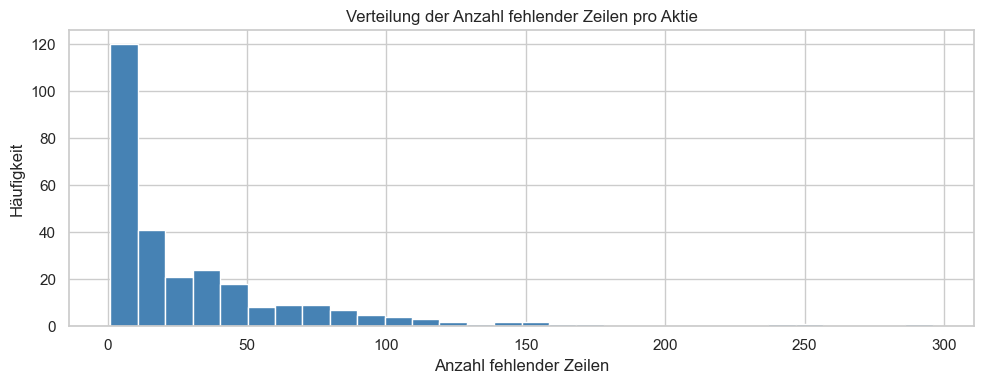


Beispielhafte fehlende Zeitpunkte:
             datetime  count
0 2025-11-07 14:31:00     29
1 2025-11-07 14:32:00     31
2 2025-11-07 14:33:00     27
3 2025-11-07 14:34:00     29
4 2025-11-07 14:35:00     19


In [32]:
# Optional: etwas schöneres seaborn-Style
sns.set(style="whitegrid")

## Inspektion der fehlenden Daten

# Sicherstellen, dass datetime als Datetime-Typ vorliegt
df["datetime"] = pd.to_datetime(df["datetime"])

# Alle Zeilen mit mindestens einem NaN
missing_rows = df[df.isna().any(axis=1)]

# Nach Ticker gruppieren und zählen
missing_by_symbol = missing_rows.groupby("symbol").size().sort_values(ascending=False)
print(f"Es gibt {len(missing_by_symbol)} Aktien mit mindestens einem fehlenden Wert.\n")
print("Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):")
print(missing_by_symbol.head(15))

# Histogramm: Verteilung fehlender Daten nach Aktie
plt.figure(figsize=(10,4))
missing_by_symbol.plot(kind="hist", bins=30, color="steelblue")
plt.title("Verteilung der Anzahl fehlender Zeilen pro Aktie")
plt.xlabel("Anzahl fehlender Zeilen")
plt.ylabel("Häufigkeit")
plt.tight_layout()
plt.show()

# Nach Zeit gruppieren und zählen
missing_by_time = missing_rows.groupby("datetime").size()

# In DataFrame umwandeln für seaborn
missing_time_df = missing_by_time.reset_index()
missing_time_df.columns = ["datetime", "count"]

print("\nBeispielhafte fehlende Zeitpunkte:")
print(missing_time_df.head())


In diesem Abschnitt wird überprüft, **welche Aktien fehlende Werte** im Datensatz haben.  
- Mit `df.isna().any(axis=1)` werden alle Zeilen markiert, die mindestens einen fehlenden Wert enthalten.
- Anschließend wird gezählt, wie viele fehlende Zeilen pro Aktie vorkommen.
Das Ergebnis zeigt: 281 Aktien haben mindestens einen fehlenden Wert.
Die Top 15 betroffenen Ticker werden ausgegeben.
- Das Histogramm visualisiert die Verteilung der Anzahl fehlender Zeilen pro Aktie:
Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte,
einige wenige jedoch deutlich mehr.

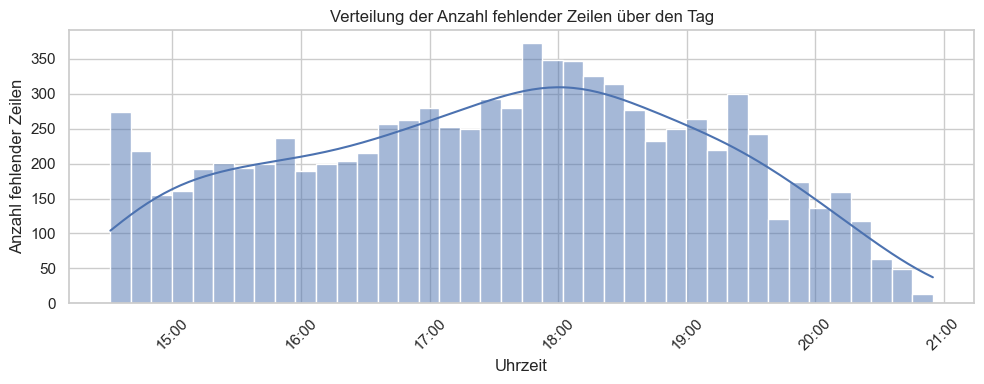

In [33]:
# Histogramm + KDE: Verteilung fehlender Daten nach Uhrzeit
plt.figure(figsize=(10,4))
sns.histplot(
    data=missing_time_df,
    x="datetime",
    weights="count",   # Anzahl fehlender Zeilen pro Zeitpunkt
    bins=40,
    kde=True
)
plt.title("Verteilung der Anzahl fehlender Zeilen über den Tag")
plt.xlabel("Uhrzeit")
plt.ylabel("Anzahl fehlender Zeilen")

# X-Achse als Uhrzeit formatieren (alle Daten stammen von einem Tag)
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Verteilung fehlender Daten über den Tag

- Hier wird mit einem **Histogramm und einer KDE-Kurve** (Dichtekurve) dargestellt,  
  zu welchen Uhrzeiten die meisten fehlenden Daten auftreten.  
- Die X-Achse zeigt die Uhrzeit, die Y-Achse die Anzahl fehlender Zeilen zu diesem Zeitpunkt.  
  Alle Daten stammen von einem einzigen Tag.
- Aus der Grafik lässt sich erkennen, dass fehlende Werte nicht gleichmäßig über den Tag verteilt sind.  
  Besonders am **Nachmittag (zwischen ca. 17:00 und 19:00 Uhr)** treten mehr fehlende Daten auf,  
  während vormittags und spätabends deutlich weniger Lücken vorkommen.

Das deutet darauf hin, dass es zu bestimmten Handelszeiten häufiger Datenlücken gab

Gefundene Lücken insgesamt: 6405

           gap_len   rel_change
count  6405.000000  6405.000000
mean      2.379859     0.000033
std       1.060093     0.001245
min       2.000000    -0.020662
25%       2.000000    -0.000510
50%       2.000000     0.000000
75%       2.000000     0.000566
max      27.000000     0.009220


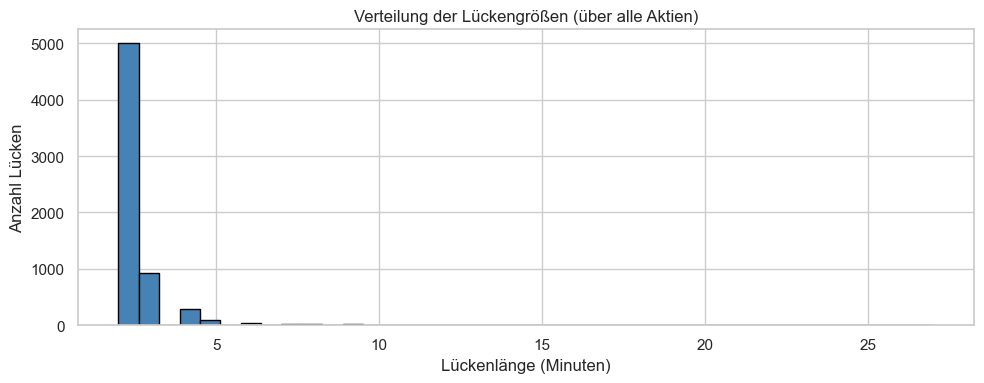

In [34]:
def analyse_nan_luecken_global(df):
    """Analysiert alle NaN-Lücken im gesamten Datensatz (über alle Aktien hinweg)."""
    normal_step = pd.Timedelta(minutes=1)
    all_gaps = []

    # Iteriere über alle Aktien, aber speichere jede Lücke einzeln
    for ticker, data in df.groupby("symbol"):
        data = data.sort_values("datetime").reset_index(drop=True)
        is_nan = data["close"].isna()

        # Wenn keine NaNs, überspringen
        if not is_nan.any():
            continue

        # Indizes der NaNs
        nan_idx = np.where(is_nan)[0]
        # Blöcke von aufeinanderfolgenden NaNs finden
        gap_blocks = np.split(nan_idx, np.where(np.diff(nan_idx) > 1)[0] + 1)

        for block in gap_blocks:
            gap_start_idx = block[0] - 1
            gap_end_idx = block[-1] + 1

            # Nur gültige Gaps mit vorher/nachher-Kurs
            if gap_start_idx < 0 or gap_end_idx >= len(data):
                continue

            t_before = data.loc[gap_start_idx, "datetime"]
            t_after = data.loc[gap_end_idx, "datetime"]
            close_before = data.loc[gap_start_idx, "close"]
            close_after = data.loc[gap_end_idx, "close"]

            if pd.isna(close_before) or pd.isna(close_after):
                continue

            # Länge der Lücke in Minuten
            gap_len = (t_after - t_before) / normal_step
            # relative Preisänderung über die Lücke
            rel_change = (close_after - close_before) / close_before

            all_gaps.append({
                "symbol": ticker,
                "gap_len": gap_len,
                "rel_change": rel_change,
            })

    return pd.DataFrame(all_gaps)

# --- Analyse ausführen ---
nan_gaps_all = analyse_nan_luecken_global(df)

print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}\n")
print(nan_gaps_all.describe())

# --- Verteilung der Lückengrößen ---
plt.figure(figsize=(10,4))
plt.hist(nan_gaps_all["gap_len"], bins=40, color="steelblue", edgecolor="black")
plt.title("Verteilung der Lückengrößen (über alle Aktien)")
plt.xlabel("Lückenlänge (Minuten)")
plt.ylabel("Anzahl Lücken")
plt.tight_layout()
plt.show()


**Analyse der NaN-Lücken im Datensatz**

- In dieser Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht.  
  Die Funktion `analyse_nan_luecken_global(df)` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten,  
  berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

- Insgesamt wurden **6 405 Lücken** gefunden.  
  Die statistische Auswertung (`describe()`) zeigt, dass die meisten Lücken kurz sind,
  im Durchschnitt etwa **2,4 Minuten**, mit maximal **27 Minuten**.

- Das Histogramm visualisiert die Verteilung der Lückengrößen:  
  Der Großteil der Lücken beträgt nur 2 Minuten, längere Ausfälle sind sehr selten.  
  Das deutet darauf hin, dass kurze Datenunterbrechungen
  regelmäßig, aber nicht gravierend auftreten.

In [35]:
# Runde Lückenlänge auf ganze Minuten (optional, falls z. B. 2.0, 2.000001 vorkommt)
nan_gaps_all["gap_len"] = nan_gaps_all["gap_len"].round().astype(int)

# Gruppieren und zählen
gap_counts = nan_gaps_all["gap_len"].value_counts().sort_index()

# Nur Lücken >= 0 Minuten (negative sollten nicht vorkommen, aber zur Sicherheit)
gap_counts = gap_counts[gap_counts.index >= 0]

# Ausgabe
print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):\n")
for gap_len, count in gap_counts.items():
    print(f"{gap_len:>4} Minuten : {count}x")


Anzahl vorkommender Lücken pro Lückengröße (in Minuten):

   2 Minuten : 4999x
   3 Minuten : 919x
   4 Minuten : 287x
   5 Minuten : 93x
   6 Minuten : 35x
   7 Minuten : 27x
   8 Minuten : 15x
   9 Minuten : 12x
  10 Minuten : 3x
  11 Minuten : 2x
  12 Minuten : 6x
  13 Minuten : 1x
  14 Minuten : 2x
  15 Minuten : 1x
  18 Minuten : 1x
  23 Minuten : 1x
  27 Minuten : 1x


**Verteilung der Lückengrößen**

- In diesem Abschnitt wird untersucht, wie häufig bestimmte Längen von Datenlücken im Datensatz vorkommen.  
  Dazu wurden die Lücken in ganze Minuten gerundet und gezählt.  

- Die Ausgabe zeigt, dass die meisten Lücken 2 Minuten lang sind (über 4900 Fälle).  
  Lücken von mehr als 5 Minuten kommen nur sehr selten vor.  


In [36]:
# Filter: nur Lücken über 5 Minuten
long_gaps = nan_gaps_all[nan_gaps_all["gap_len"] > 5]

# Aktien, die mindestens eine solche Lücke haben
symbols_with_long_gaps = long_gaps["symbol"].unique()

print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(symbols_with_long_gaps)}\n")

print("Aktien mit langen Lücken (> 5 Minuten):")
for sym in symbols_with_long_gaps:
    n_luecken = len(long_gaps[long_gaps["symbol"] == sym])
    max_gap = long_gaps[long_gaps["symbol"] == sym]["gap_len"].max()
    print(f"  {sym} — {n_luecken} Lücken (max. {max_gap:.0f} Minuten)")


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 27

Aktien mit langen Lücken (> 5 Minuten):
  AIZ — 3 Lücken (max. 6 Minuten)
  ALGN — 1 Lücken (max. 7 Minuten)
  AVY — 2 Lücken (max. 8 Minuten)
  BR — 1 Lücken (max. 9 Minuten)
  CINF — 5 Lücken (max. 8 Minuten)
  DOV — 1 Lücken (max. 7 Minuten)
  DRI — 1 Lücken (max. 6 Minuten)
  ERIE — 19 Lücken (max. 11 Minuten)
  GL — 1 Lücken (max. 7 Minuten)
  GPC — 1 Lücken (max. 6 Minuten)
  GWW — 6 Lücken (max. 9 Minuten)
  J — 1 Lücken (max. 6 Minuten)
  L — 2 Lücken (max. 7 Minuten)
  LDOS — 1 Lücken (max. 9 Minuten)
  MLM — 1 Lücken (max. 6 Minuten)
  NDSN — 15 Lücken (max. 18 Minuten)
  NVR — 21 Lücken (max. 27 Minuten)
  NWS — 4 Lücken (max. 7 Minuten)
  PKG — 5 Lücken (max. 9 Minuten)
  SBAC — 1 Lücken (max. 9 Minuten)
  SNA — 1 Lücken (max. 7 Minuten)
  TDY — 3 Lücken (max. 8 Minuten)
  TPL — 4 Lücken (max. 8 Minuten)
  TRMB — 1 Lücken (max. 6 Minuten)
  TYL — 2 Lücken (max. 7 Minuten)
  UHS — 3 Lücken (max. 6 Minuten)
  WTW — 1 L

Dieser Codeblock filtert aus der zuvor berechneten Tabelle nan_gaps_all alle Lücken mit einer Länge größer als 5 Minuten heraus und identifiziert die betroffenen Aktien. Anschließend werden die Anzahl betroffener Ticker ausgegeben und für jeden Ticker die Anzahl der langen Lücken sowie die maximale Lückenlänge angezeigt.

Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:

    gap_length_min  n_stocks
0                1       281
1                2       281
2                3       154
3                4        83
4                5        49
5                6        27
6                7        19
7                8        12
8                9         8
9               10         3
10              11         3
11              12         2
12              13         2
13              14         2
14              15         2
15              16         2
16              17         2
17              18         2
18              19         1
19              20         1


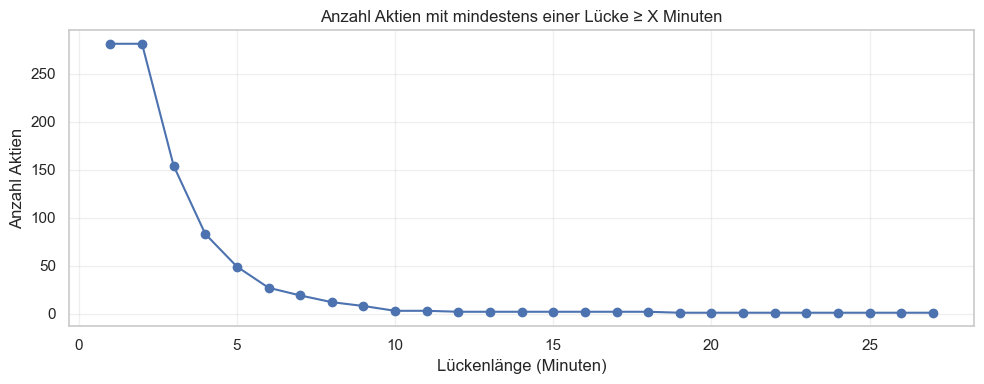

In [37]:
import numpy as np

# Runde Lückenlängen auf ganze Minuten
nan_gaps_all["gap_len"] = nan_gaps_all["gap_len"].round().astype(int)

# Maximale Lücke pro Aktie bestimmen
max_gap_per_symbol = (
    nan_gaps_all.groupby("symbol")["gap_len"].max()
)

# Alle möglichen Längen von 1 bis zur größten beobachteten Lücke
max_len = int(max_gap_per_symbol.max())
minutes = np.arange(1, max_len + 1)

# Für jede Minutenlänge: wie viele Aktien haben >= diese Länge
stocks_with_min_gap = [
    (max_gap_per_symbol >= m).sum() for m in minutes
]

# Ergebnis in DataFrame
gap_stats = pd.DataFrame({
    "gap_length_min": minutes,
    "n_stocks": stocks_with_min_gap
})

# Ausgabe
print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:\n")
print(gap_stats.head(20))  # erste 20 Zeilen

# Optional: Plot
plt.figure(figsize=(10,4))
plt.plot(gap_stats["gap_length_min"], gap_stats["n_stocks"], marker="o")
plt.title("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten")
plt.xlabel("Lückenlänge (Minuten)")
plt.ylabel("Anzahl Aktien")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [38]:
# Schritt 1: Ermittle maximale Lückenlänge pro Aktie
max_gap_per_symbol = nan_gaps_all.groupby("symbol")["gap_len"].max()

# Schritt 2: Finde alle Aktien mit mindestens einer Lücke ≥ 6 Minuten
symbols_with_long_gaps = max_gap_per_symbol[max_gap_per_symbol >= 6].index
print(f"Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: {len(symbols_with_long_gaps)}")

# Schritt 3: Entferne diese Aktien aus dem Haupt-DataFrame
df_clean = df[~df["symbol"].isin(symbols_with_long_gaps)].copy()

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")


Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: 27
Verbleibende Aktien nach Filterung: 476


In [39]:
# Sicherstellen, dass sortiert und datetime korrekt ist
df_clean = df_clean.sort_values(["symbol", "datetime"]).copy()
df_clean["datetime"] = pd.to_datetime(df_clean["datetime"])

def fill_close_gaps(group):
    # Nach Zeit sortieren und datetime als Index setzen
    group = group.sort_values("datetime").set_index("datetime")

    s = group["close"]

    # 1) Innenliegende Lücken interpolieren (nur dort, wo davor und danach Werte existieren)
    s_interp = s.interpolate(method="time", limit_area="inside")

    # 2) Ränder auffüllen:
    #    - am Anfang: mit erstem gültigen Wert (bfill)
    #    - am Ende: mit letztem gültigen Wert (ffill)
    s_filled = s_interp.bfill().ffill()

    group["close_filled"] = s_filled

    return group.reset_index()

# Auf alle (gefilterten) Aktien anwenden
df_filled = df_clean.groupby("symbol", group_keys=False).apply(fill_close_gaps)

# Kontrolle
print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())


Fehlende Werte im Original (gefiltert): 5423
Fehlende Werte in close_filled: 0


C:\Users\ilija\AppData\Local\Temp\ipykernel_44732\3315039951.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_filled = df_clean.groupby("symbol", group_keys=False).apply(fill_close_gaps)


In [40]:
print("Analyse der Längen pro Aktie\n")

# Anzahl Zeilen pro Symbol
lengths = df_filled.groupby("symbol").size().sort_values()

print("\nHäufigste Längen:")
print(lengths.value_counts().sort_index())

Analyse der Längen pro Aktie


Häufigste Längen:
390      2
391    474
Name: count, dtype: int64


In [41]:
expected_length = 391
lengths = df_filled.groupby("symbol").size()
bad_symbols = lengths[lengths != expected_length]
print("Aktien mit abweichender Länge:\n")
print(bad_symbols.sort_values())

Aktien mit abweichender Länge:

symbol
DD    390
TT    390
dtype: int64


In [42]:
symbols_to_drop = ["DD", "TT"]
df_filled = df_filled[~df_filled["symbol"].isin(symbols_to_drop)].copy()

print(f"Entfernte Symbole: {symbols_to_drop}")
print(f"Verbleibende Aktien: {df_filled['symbol'].nunique()}")

Entfernte Symbole: ['DD', 'TT']
Verbleibende Aktien: 474


Paarsuche

In [43]:
# Pivot-Tabelle: Zeilen = Zeit, Spalten = Symbol, Werte = Close
price_matrix = df_filled.pivot(index="datetime", columns="symbol", values="close_filled")

# Optional: Logarithmieren (reduziert Trends, stabilisiert Varianz)
log_prices = np.log(price_matrix)

## Ziel und Analyse der Korrelations-Heatmap

Das Hauptziel dieser Analyse war es, **stark korrelierte Aktienpaare** zu identifizieren, also Aktien, deren Kursverläufe sich mit einem sehr hohen linearen Zusammenhang entwickeln (Korrelation r > 0.97).  
Dies ist besonders interessant, um **Muster, Zusammenhänge oder mögliche Arbitragemöglichkeiten** zwischen Aktien zu erkennen.

### Vorgehensweise
1. **Berechnung der Korrelationsmatrix (`corr`)**  
   Alle Aktienpreise wurden paarweise miteinander korreliert, um zu messen, wie ähnlich sich deren Kursbewegungen über den betrachteten Zeitraum verhalten.

2. **Filterung stark korrelierter Paare (r > 0.97)**  
   Nur Aktienpaare mit einem sehr hohen Korrelationswert wurden behalten.  
   → Insgesamt wurden **19 stark korrelierte Aktienpaare** gefunden.

3. **Auswahl der relevantesten Aktien**  
   Aus diesen Paaren wurden die Aktien mit den **höchsten durchschnittlichen Korrelationen** ausgewählt, um die Top-19-Aktien zu bestimmen, die am stärksten miteinander verbunden sind.

4. **Visualisierung als Heatmap**  
   Die resultierende Teilmatrix wurde in einer **Korrelations-Heatmap** dargestellt, wobei:
   - **Rote Felder** = hohe positive Korrelation (ähnliche Kursverläufe)  
   - **Blaue Felder** = geringere oder negative Korrelation  
   - **Weiße Diagonale** = Selbstkorrelation (immer = 1)

### Interpretation der Ergebnisse
- **Hohe Homogenität der Top-Aktien:**  
  Fast alle Aktien innerhalb der Top-19 zeigen **starke positive Korrelationen (>0.75)**, was bedeutet, dass sie sich **ähnlich entwickeln**.  
  Solche Titel reagieren häufig auf **gleiche Marktbedingungen oder Branchentrends**.

- **Clusterbildung:**  
  Es bilden sich Gruppen von Aktien, die besonders stark miteinander korrelieren. Diese Cluster können auf **Sektorzugehörigkeiten** oder **ähnliche Geschäftsmodelle** hinweisen.

- **Starke lineare Beziehungen:**  
  Werte nahe 1 (r ≈ 0.97–0.99) deuten darauf hin, dass zwischen diesen Aktien eine fast **lineare Beziehung** besteht – wenn die eine steigt, steigt die andere mit hoher Wahrscheinlichkeit ebenfalls.



19 stark korrelierte Paare gefunden (r > 0.97)

Min/Max der Off-Diagonal-Korrelationen: 0.7584369938968464 0.9686010927425059


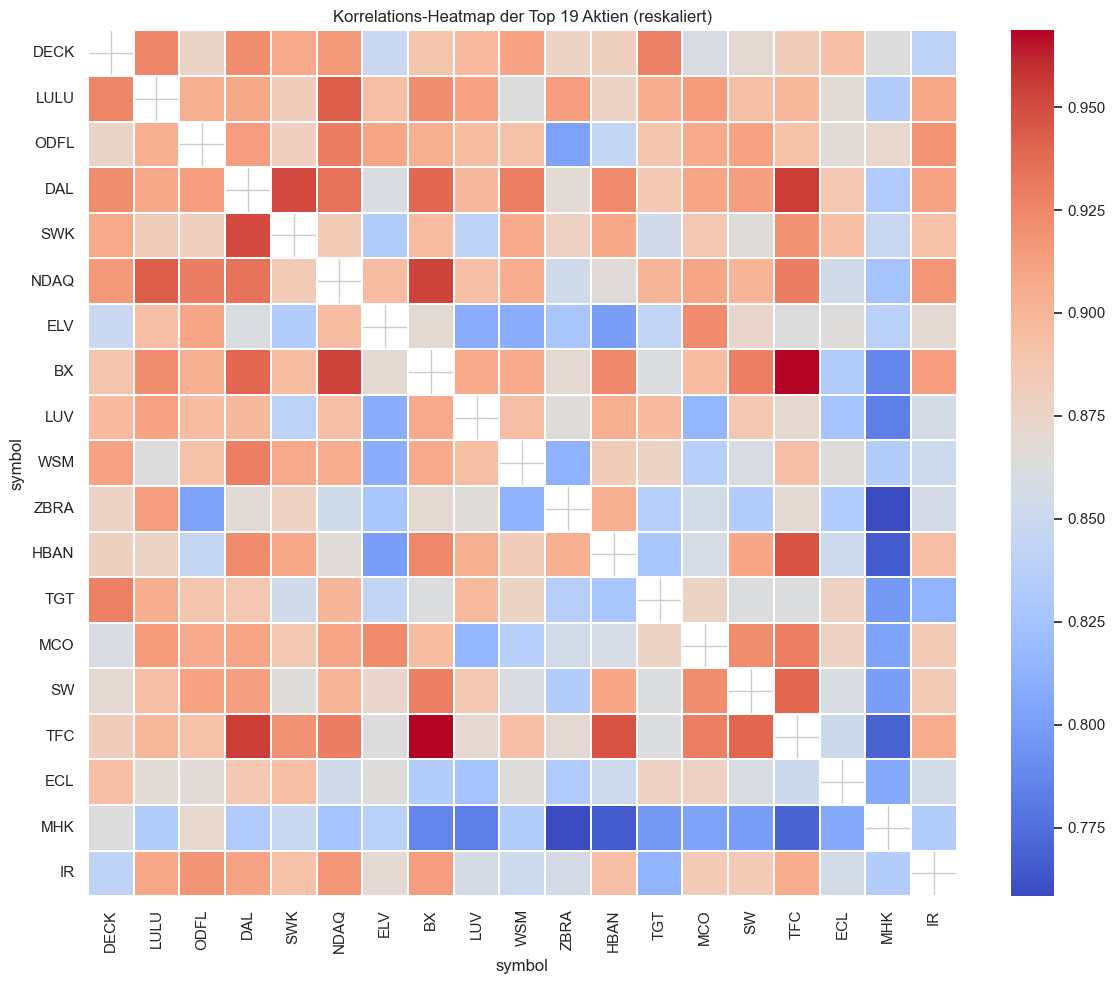

In [44]:
import numpy as np

corr = log_prices.corr()
strong_corr_pairs = [
    (i, j)
    for i in corr.columns
    for j in corr.columns
    if i < j and corr.loc[i, j] > 0.97
]
print(f"{len(strong_corr_pairs)} stark korrelierte Paare gefunden (r > 0.97)")

# Mittelwerte der Korrelationen (um "relevante" Aktien zu finden)
mean_corr = corr.mean().sort_values(ascending=False)

# Top-N Aktien mit höchsten durchschnittlichen Korrelationen
top_n_heatmap = 19
top_symbols = mean_corr.head(top_n_heatmap).index

# Submatrix der Top-N Aktien
corr_sub = corr.loc[top_symbols, top_symbols]

# Diagonale maskieren (1.0-Werte)
mask = np.eye(len(corr_sub), dtype=bool)

# Off-Diagonal-Werte für Min/Max bestimmen
offdiag = corr_sub.where(~pd.DataFrame(mask, index=corr_sub.index, columns=corr_sub.columns))
vmin = offdiag.min().min()
vmax = offdiag.max().max()
print("\nMin/Max der Off-Diagonal-Korrelationen:", vmin, vmax)

# Heatmap mit reskalierter Farbskala
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=False,
    linewidths=0.2
)
plt.title(f"Korrelations-Heatmap der Top {top_n_heatmap} Aktien (reskaliert)")
plt.tight_layout()
plt.show()

### Ziel und Analyse des Cointegrations-Netzwerks

Das Ziel dieser Analyse ist es, **stark cointegrierte Aktienpaare** zu identifizieren – also Aktien, deren Preisverläufe zwar individuell schwanken, sich aber langfristig **gemeinsam in einem stabilen Gleichgewicht** bewegen.  
Dies ist besonders relevant für **statistische Arbitrage** und **Pair-Trading-Strategien**, da solche Beziehungen auf **langfristig stabile Preisverhältnisse** hinweisen.


### Vorgehensweise
1. **Grundlage: Starke Korrelationen**  
   Aus der vorherigen Analyse wurden Aktienpaare mit hoher Korrelation (r > 0.97) ausgewählt – diese dienen als Ausgangspunkt für den Cointegrationstest.

2. **Engle-Granger-Cointegrationstest**  
   Für jedes dieser Paare wurde der **p-Wert** des Tests berechnet.  
   - Wenn **p < 0.05**, wird die Nullhypothese verworfen, d. h. es besteht **eine signifikante Cointegration**.  
   - Diese Paare wurden in einer Tabelle und anschließend in einem **Netzwerkdiagramm** visualisiert.

3. **Netzwerkdarstellung (Graph)**  
   - **Knoten (Nodes)** = einzelne Aktien  
   - **Kanten (Edges)** = cointegrationsbasierte Verbindungen (p < 0.05) 


### Interpretation der Ergebnisse
- Es wurden **10 signifikante Cointegrationskanten (p < 0.05)** gefunden.  
  Diese Verbindungen zeigen Paare, deren Preisverhältnisse **langfristig stationär** sind – d. h. sie kehren immer wieder zu einem Gleichgewicht zurück.

- **Zentralität der Knoten:**  
  - **PNC**, **IBKR**, und **STT** bilden zentrale Hubs im Netzwerk – sie sind mit mehreren anderen Aktien cointegrativ verbunden.  
  - Dies deutet darauf hin, dass diese Titel **starke gemeinsame Langfristbeziehungen** mit verschiedenen Aktien aufweisen.

- **Beispielhafte Cluster:**
  - **PNC – IBKR – BK – MTB – CFG**: Ein stark verbundenes Cluster, wahrscheinlich aus **Bank- und Finanzwerten**.
  - **FOX – FOXA – STT – NTRS**: Ein weiteres, schwächeres Cluster, möglicherweise durch **ähnliche Marktstrukturen oder Branchenexposition** verbunden.
  - **NVDA – MPWR**: Ein technologiebasiertes Paar mit signifikanter Cointegration (p = 0.044).

### Schlussfolgerungen
1. **Ziel erreicht:**  
   Die Analyse hat **mehrere stark cointegrative Aktienpaare** identifiziert, was auf **langfristig stabile Preisbeziehungen** hindeutet.

2. **Handelsstrategische Relevanz:**  
   - Diese Beziehungen können für **statistische Arbitrage** genutzt werden.  
     Wenn sich die Preisdifferenz zweier cointegrativer Aktien kurzfristig auseinanderbewegt, könnte eine Rückkehr zur Balance (Mean-Reversion) erwartet werden.
   - Damit sind diese Paare potenziell **interessante Kandidaten für Pair-Trading**.

3. **Struktur des Netzwerks:**  
   - Aktien mit vielen Verbindungen (hohem Grad) reagieren tendenziell **ähnlich auf fundamentale oder makroökonomische Einflüsse**.  
   - Isolierte Verbindungen (z. B. NVDA–MPWR) zeigen **spezifische, sektorbasierte Cointegration**, die sich gezielt handeln lässt.


Anzahl Kanten mit p < 0.05: 10


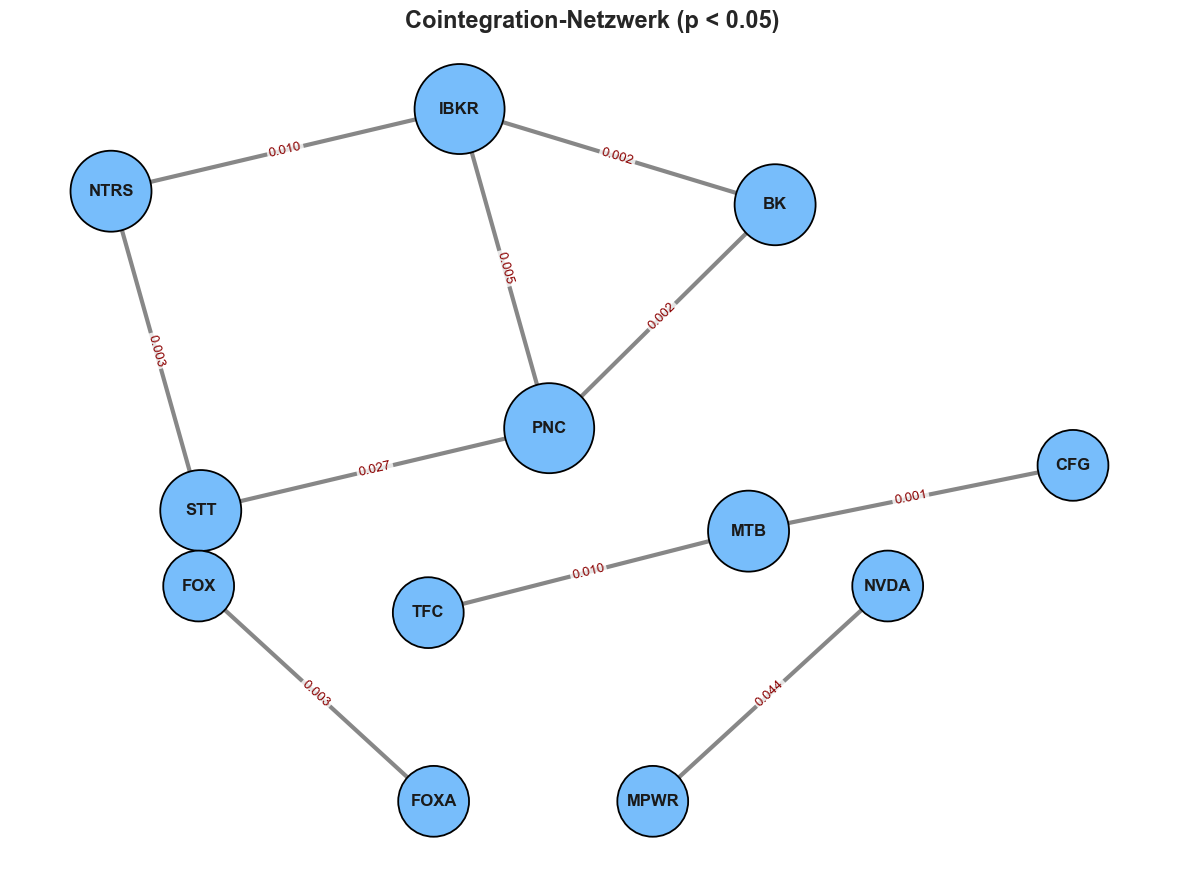

In [45]:
# --- Cointegration wie bisher ---
coint_results = []

for s1, s2 in strong_corr_pairs:
    series1 = log_prices[s1].dropna()
    series2 = log_prices[s2].dropna()
    if len(series1) != len(series2):
        continue

    score, pvalue, _ = coint(series1, series2)
    coint_results.append((s1, s2, pvalue))

coint_df = pd.DataFrame(coint_results, columns=["symbol1", "symbol2", "pvalue"])
coint_df = coint_df.sort_values("pvalue")

# --- Graph aus den Cointegrationspaaren bauen ---

# nur Paare mit "guter" Cointegration nehmen (z.B. p < 0.05)
threshold = 0.05
edges_df = coint_df[coint_df["pvalue"] < threshold]

print(f"Anzahl Kanten mit p < {threshold}: {len(edges_df)}")

G = nx.Graph()

for _, row in edges_df.iterrows():
    s1, s2, pv = row["symbol1"], row["symbol2"], row["pvalue"]
    G.add_edge(s1, s2, pvalue=pv)

if G.number_of_edges() == 0:
    print("Keine Cointegrationspaare unterhalb des p-Schwellenwerts gefunden.")
else:
    plt.figure(figsize=(12, 9))

    # Größere Abstände mit "scale" und mehr Iterationen
    pos = nx.kamada_kawai_layout(G, scale=5.0)  # Standard ist 1.0 → größer = mehr Abstand

    # Knoten deutlich größer und etwas stärker skaliert nach Grad
    degrees = dict(G.degree())
    node_sizes = [1800 + degrees[n] * 800 for n in G.nodes()]

    # Nodes
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color="#77bdfb",
        node_size=node_sizes,
        edgecolors="black",
        linewidths=1.3
    )

    # Edges
    nx.draw_networkx_edges(
        G,
        pos,
        width=3,
        edge_color="#555555",
        alpha=0.7
    )

    # Node-Labels
    nx.draw_networkx_labels(
        G,
        pos,
        font_size=12,
        font_weight="bold"
    )

    # p-Werte als Labels auf den Kanten
    edge_labels = {(u, v): f"{d['pvalue']:.3f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=9.5,
        font_color="darkred",
        label_pos=0.5,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8)
    )

    plt.title(f"Cointegration-Netzwerk (p < {threshold})", fontsize=17, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Ziel und Analyse der normierten Preisverläufe der Top 5 cointegrierten Aktienpaare

Das Ziel dieser Analyse ist es, die **zeitliche Preisentwicklung der am stärksten cointegrierten Aktienpaare** zu visualisieren.  
Durch die Normierung der Preise werden die relativen Bewegungen besser vergleichbar und es lässt sich erkennen, ob sich die Paare langfristig **gemeinsam im Gleichgewicht** bewegen — das zentrale Merkmal von Cointegration.


### Vorgehensweise

1. **Auswahl der Top 5 Cointegrationspaare**  
   Aus der vorherigen Cointegrationsanalyse wurden die fünf Paare mit den **niedrigsten p-Werten (p < 0.05)** ausgewählt.  
   Diese Paare weisen die **stärkste statistische Cointegration** auf.

2. **Exponentielle Transformation und Normierung**  
   - Die logarithmierten Kursdaten wurden exponentiell zurücktransformiert, um wieder Preise zu erhalten.  
   - Danach wurden die Preisreihen **auf denselben Startwert (1.0)** normiert, damit sie direkt vergleichbar sind.

3. **Visualisierung**  
   - Jedes Diagramm zeigt ein Aktienpaar mit seinem zugehörigen **p-Wert**.  
   - Die Linienverläufe zeigen, wie sich beide Aktien **gemeinsam über die Zeit bewegen**.

### Interpretation der Ergebnisse

#### 1. **CFG vs MTB | p = 0.0008**
   - Sehr starke Cointegration.  
   - Beide Aktien verlaufen über weite Strecken nahezu identisch.  
   - Temporäre Abweichungen (z. B. gegen Ende) sind gering und deuten auf eine schnelle Rückkehr zum Gleichgewicht hin.

#### 2. **BK vs IBKR | p = 0.0020**
   - Beide Kurse zeigen eine stabile, parallele Bewegung mit leichter Divergenz in der Mitte.  
   - Typisch für ein Paar, das **mittelfristige Spread-Schwankungen** aufweist, aber **langfristig stabil** bleibt.

#### 3. **BK vs PNC | p = 0.0024**
   - Wieder eine sehr ähnliche Preisentwicklung.  
   - Beide Aktien bewegen sich fast synchron, was die starke Cointegration bestätigt.  
   - Besonders interessant für **Pair-Trading**, da kurzfristige Abweichungen handelbar sein könnten.

#### 4. **NTRS vs STT | p = 0.0030**
   - Nahezu identische Preisverläufe über den gesamten Zeitraum.  
   - Beide Werte reagieren ähnlich auf Marktschwankungen – vermutlich aus demselben Sektor (Banken/Finanzwesen).  
   - Ein klassisches Beispiel für ein **robustes cointegratives Paar**.

#### 5. **FOX vs FOXA | p = 0.0033**
   - Wie zu erwarten, extrem ähnliche Kursbewegungen (beides Aktien derselben Unternehmensgruppe).  
   - Der Spread bleibt eng und stabil – eine **ideale Cointegration**.


### Schlussfolgerungen

1. **Ziel erreicht:**  
   Die Top-5-Paare zeigen alle **starke Cointegration** (p < 0.01), was auf **langfristig stabile Preisverhältnisse** hinweist.

2. **Stabilität und Branchenabhängigkeit:**  
   - Mehrere Paare stammen aus dem **Finanzsektor** (z. B. CFG–MTB, BK–PNC, NTRS–STT), was auf **gemeinsame Marktmechanismen** hinweist.  
   - FOX–FOXA zeigt hingegen eine **strukturelle Verbindung** (gleiche Unternehmensgruppe) – ein Paradebeispiel für perfekte Cointegration.




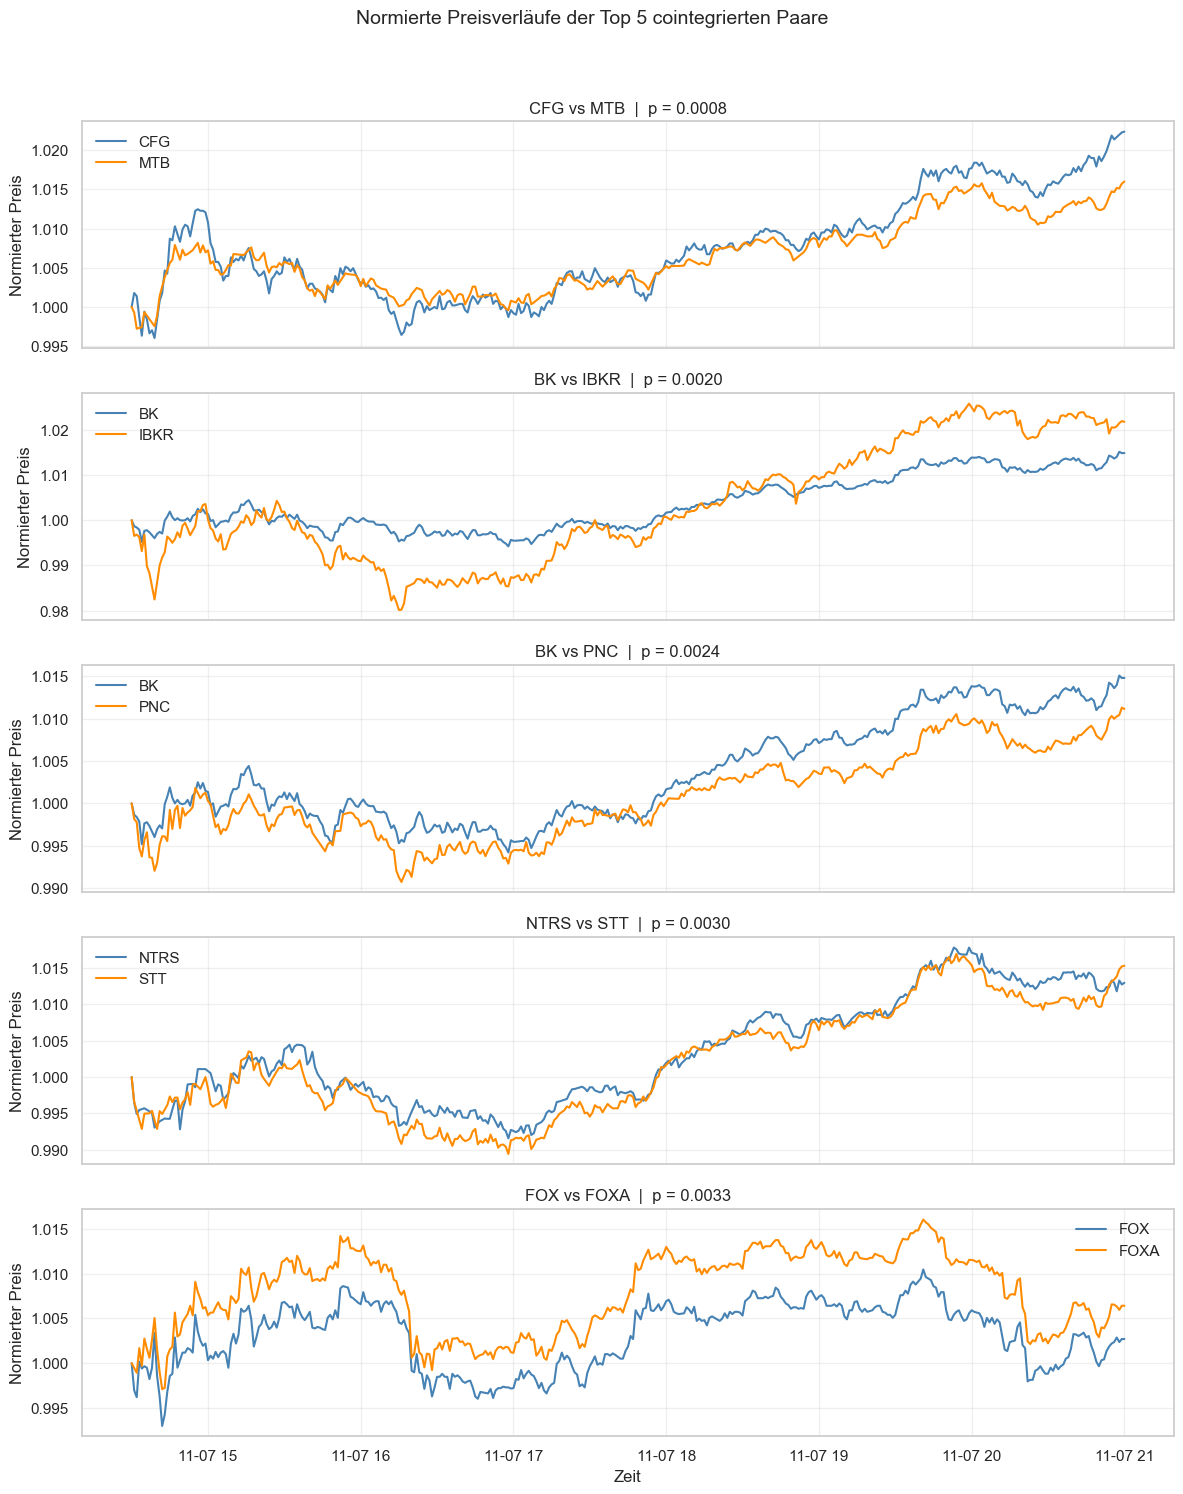

In [46]:
top_n = 5
top_pairs = coint_df.head(top_n)

fig, axes = plt.subplots(top_n, 1, figsize=(12, 3 * top_n), sharex=True)

for idx, (i, row) in enumerate(top_pairs.iterrows()):
    s1, s2, pval = row["symbol1"], row["symbol2"], row["pvalue"]

    # Preisreihen
    p1, p2 = log_prices[s1].copy(), log_prices[s2].copy()

    # Exponentiell zurücktransformieren, um Preise zu bekommen
    p1, p2 = np.exp(p1), np.exp(p2)

    # Normieren auf 1 am Startzeitpunkt
    p1_norm = p1 / p1.iloc[0]
    p2_norm = p2 / p2.iloc[0]

    ax = axes[idx]
    ax.plot(p1_norm, label=s1, color="steelblue")
    ax.plot(p2_norm, label=s2, color="darkorange")
    ax.set_title(f"{s1} vs {s2}  |  p = {pval:.4f}")
    ax.set_ylabel("Normierter Preis")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Zeit")
plt.suptitle("Normierte Preisverläufe der Top 5 cointegrierten Paare", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Ziel und Analyse der Spread-Mean-Reversion bei den Top 5 cointegrierten Aktienpaaren

Das Ziel dieser Analyse ist es, die **stationären Spreads (log-Preis-Differenzen)** der am stärksten cointegrierten Aktienpaare zu untersuchen und deren Verhalten im Verhältnis zu ihrem **langfristigen Mittelwert** zu bewerten.  
Ein **stabiler Spread**, der regelmäßig um einen Mittelwert schwankt, ist ein direktes Zeichen für **Cointegration** und somit für **Mean-Reversion-Potenzial**.


### Vorgehensweise

**Berechnung des Spreads:**  
   Der Spread zwischen zwei Aktien wurde berechnet als:  
  {Spread}(t) = \log(P_1(t)) - \log(P_2(t))  
   Dadurch wird der Preisunterschied in Prozent-ähnliche Einheiten transformiert, was Vergleiche zwischen Aktien mit unterschiedlichen Preisniveaus ermöglicht.

 **Bestimmung des Mittelwerts:**  
   Für jede Paarzeitreihe wurde der **durchschnittliche Spread** berechnet und als **rote gestrichelte Linie** eingezeichnet.  
   Dieser Mittelwert repräsentiert das **langfristige Gleichgewichtsniveau** zwischen den beiden Aktien.

**Visualisierung:**  
   - **Blaue Linie:** Zeitlicher Verlauf des Spreads (log-Preis-Differenz)  
   - **Rote Linie:** Mittelwert (Gleichgewicht)  
   - **p-Wert:** Signifikanz der Cointegration (je kleiner, desto stärker die Beziehung)


### Interpretation der Ergebnisse

#### **1. CFG vs MTB | p = 0.0008**
   - Der Spread schwankt eng um den Mittelwert (-1.2848).  
   - Deutliche Rückkehrbewegungen nach Ausschlägen: **Mean-Reversion-Effekt**.  
   - Stark cointegriertes Paar, ideal für **statistische Arbitrage**.

#### **2. BK vs IBKR | p = 0.0020**
   - Langsam abnehmender Spread mit sichtbarer Rückkehr zum Mittelwert in der Mitte des Zeitraums.  
   - Zeigt **langfristige Stabilität**, trotz temporärer Trendbewegung.  
   - Moderate, aber signifikante Cointegration.

#### **3. BK vs PNC | p = 0.0024**
   - Spread oszilliert regelmäßig um den Mittelwert (-0.5197).  
   - Gute Balance zwischen Schwankung und Rückkehrbewegung.  
   - Typisches Verhalten für **gleichartige Finanzwerte** mit strukturellem Gleichgewicht.

#### **4. NTRS vs STT | p = 0.0030**
   - Beide Aktien bewegen sich in einem **engen, stationären Spreadbereich** (0.09–0.10).  
   - Zeigt häufige Rückkehrbewegungen: **Mean-Reversion-Effekt**.  
   - Solider Kandidat für Pair-Trading im Bankensektor.

#### **5. FOX vs FOXA | p = 0.0033**
   - Sehr enger Spread um -0.1046, nahezu konstant über den Zeitraum.  
   - Minimaler Trend und klare Rückkehr zum Mittelwert.  


### Schlussfolgerungen

1. **Ziel erreicht:**  
   Die Visualisierung zeigt, dass alle Paare um einen stabilen Mittelwert schwanken.
2. **Handelsrelevanz:**  
   - Wenn der Spread **oberhalb des Mittelwerts** liegt → Aktie 1 ist relativ **überbewertet**, Aktie 2 **unterbewertet**.  
   - Wenn der Spread **unterhalb des Mittelwerts** liegt → umgekehrte Positionierung.



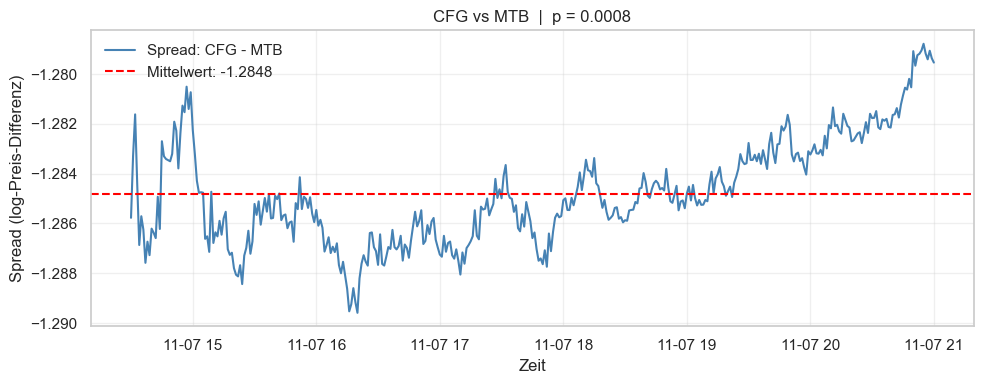

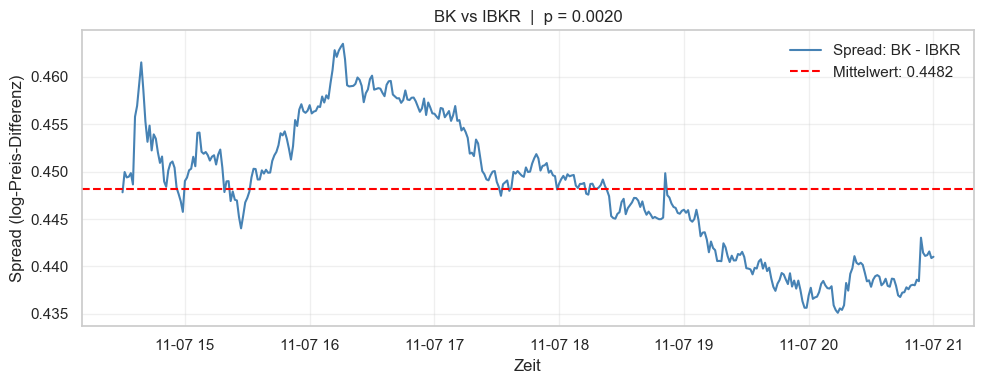

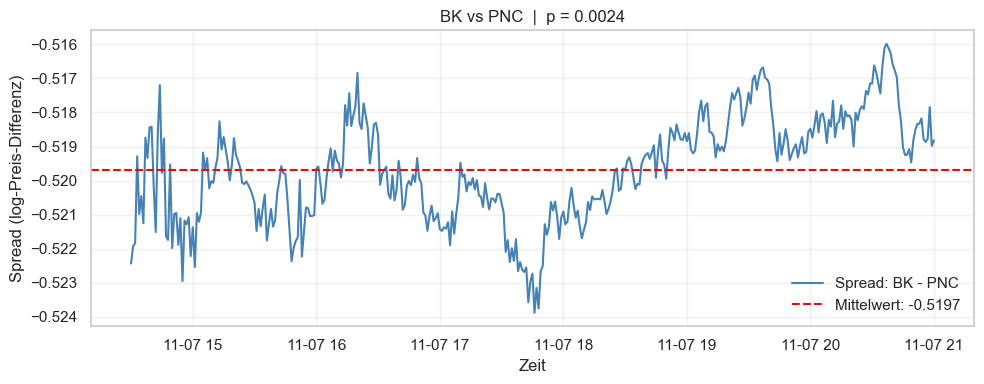

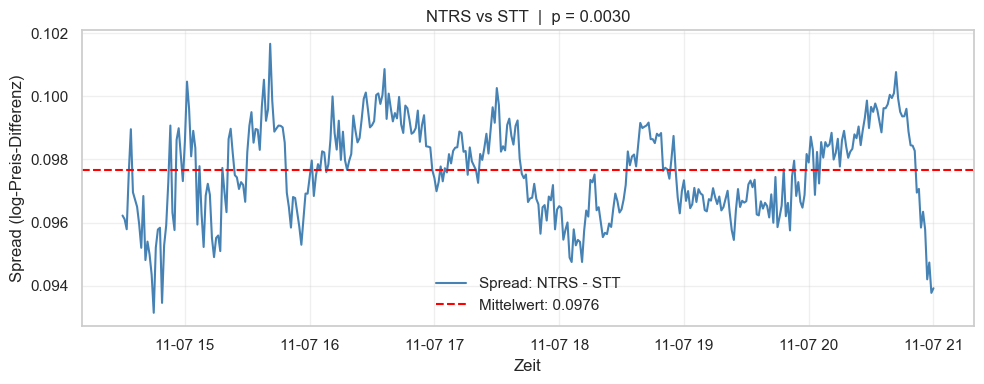

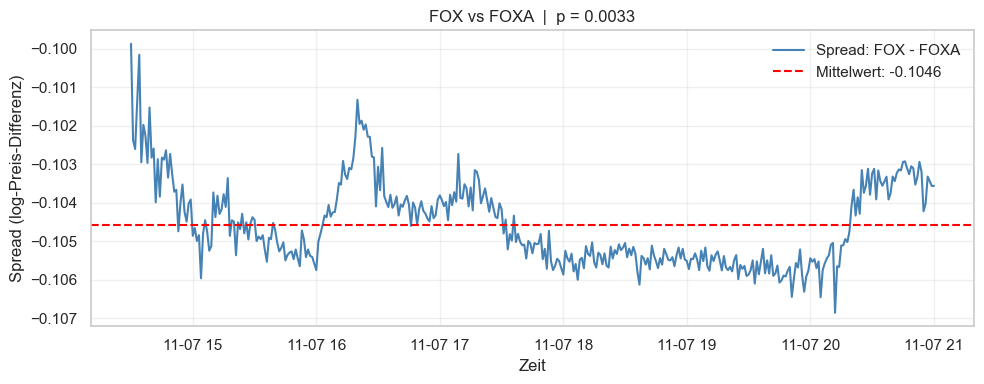

In [ ]:
top_pairs = coint_df.head(top_n)

for i, row in top_pairs.iterrows():
    s1, s2, pval = row["symbol1"], row["symbol2"], row["pvalue"]
    spread = log_prices[s1] - log_prices[s2]
    mean_spread = spread.mean()  # Mittelwert berechnen

    plt.figure(figsize=(10, 4))
    plt.plot(spread, label=f"Spread: {s1} - {s2}", color='steelblue')
    plt.axhline(y=mean_spread, color='red', linestyle='--', 
                label=f'Mittelwert: {mean_spread:.4f}')
    
    plt.title(f"{s1} vs {s2}  |  p = {pval:.4f}")
    plt.xlabel("Zeit")
    plt.ylabel("Spread (log-Preis-Differenz)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()